In [1]:
pip install speechbrain torchaudio scikit-learn soundfile

  Using cached torch-2.14.1-cp310-cp310-macosx_14_0_arm64.whl.metadata (38 kB)
  Using cached torchaudio-2.11.0-cp310-cp310-macosx_11_0_arm64.whl.metadata (6.9 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 912.7/912.7 kB 19.4 MB/s  0:00:00
Using cached torchaudio-2.11.0-cp310-cp310-macosx_11_0_arm64.whl (684 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 18.1 MB/s  0:00:00
Using cached torch-2.14.1-cp310-cp310-macosx_14_0_arm64.whl (127.2 MB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
  Attempting uninstall: torchaudio
    Found existing installation: torchaudio 2.5.1
    Uninstalling torchaudio-2.5.1:
      Successfully uninstalled torchaudio-2.5.1
  Attempting uninstall: sympy
    Found existing installation: sympy 1.13.1
    Uninstalling sympy-1.13.1:╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/8 [sympy]
      Successfully uninstalled sympy-1.13.1━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/8 [sympy]
  Attempting 

In [6]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import torch
import torchaudio
import torch.nn.functional as F
from speechbrain.inference.speaker import EncoderClassifier
from sklearn.metrics import accuracy_score, classification_report

import soundfile as sf
import torch.nn.functional as F
from scipy.signal import resample_poly
from math import gcd

# Project paths
timit_dir = Path("../data/raw/timit").resolve()
generated_dir = Path("../data/processed/generated").resolve()
manifest_path = Path("../data/evaluation/vc_test_manifest.csv").resolve()

# Load pretrained speaker-recognition model
device = "cuda" if torch.cuda.is_available() else "cpu"

speaker_model = EncoderClassifier.from_hparams(
    source="speechbrain/spkrec-ecapa-voxceleb",
    run_opts={"device": device}
)

def get_embedding(audio_path):
    """Extract a normalized speaker embedding from a WAV file."""

    # Read audio using SoundFile
    audio, sample_rate = sf.read(
        str(audio_path),
        dtype="float32",
        always_2d=True
    )

    # Convert stereo to mono
    audio = audio.mean(axis=1)

    # Resample to 16 kHz if needed
    if sample_rate != 16000:
        divisor = gcd(sample_rate, 16000)
        audio = resample_poly(
            audio,
            16000 // divisor,
            sample_rate // divisor
        ).astype(np.float32)

    # Convert to tensor with shape [batch, samples]
    waveform = torch.from_numpy(
        np.ascontiguousarray(audio)
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        embedding = speaker_model.encode_batch(waveform)

    embedding = embedding.squeeze().cpu()
    return F.normalize(embedding, p=2, dim=0)

In [7]:
speaker_embeddings = {}

real_audio_files = [
    p for p in timit_dir.joinpath("train").rglob("*")
    if p.is_file() and p.suffix.lower() == ".wav"
]

for audio_path in real_audio_files:
    speaker_id = audio_path.parent.name.upper()

    try:
        embedding = get_embedding(audio_path)
        speaker_embeddings.setdefault(speaker_id, []).append(embedding)
    except Exception as e:
        print(f"Skipping {audio_path.name}: {e}")

# Average and normalize each speaker profile
speaker_profiles = {}

for speaker_id, embeddings in speaker_embeddings.items():
    profile = torch.stack(embeddings).mean(dim=0)
    speaker_profiles[speaker_id] = F.normalize(profile, p=2, dim=0)

print("Speaker profiles created:", len(speaker_profiles))

Speaker profiles created: 431


In [8]:
manifest = pd.read_csv(manifest_path)
classification_results = []

for _, row in manifest.iterrows():
    audio_path = Path(row["generated_audio"])
    target_speaker = str(row["target_speaker"]).strip().upper()

    # Only evaluate speakers for whom we have a real reference profile
    if target_speaker not in speaker_profiles:
        continue

    if not audio_path.exists():
        continue

    try:
        generated_embedding = get_embedding(audio_path)

        similarities = {
            speaker: torch.dot(generated_embedding, profile).item()
            for speaker, profile in speaker_profiles.items()
        }

        predicted_speaker = max(similarities, key=similarities.get)

        classification_results.append({
            "generated_audio": str(audio_path),
            "target_speaker": target_speaker,
            "predicted_speaker": predicted_speaker,
            "correct": predicted_speaker == target_speaker,
            "cosine_similarity": similarities[predicted_speaker]
        })

    except Exception as e:
        print(f"Error processing {audio_path.name}: {e}")

results_df = pd.DataFrame(classification_results)

if not results_df.empty:
    accuracy = accuracy_score(
        results_df["target_speaker"],
        results_df["predicted_speaker"]
    )

    print(f"Evaluated files: {len(results_df)}")
    print(f"Speaker classification accuracy: {accuracy:.4f}")
    print(f"Speaker classification accuracy (%): {accuracy * 100:.2f}%")

    results_path = Path("../data/evaluation/speaker_classification_results.csv")
    results_path.parent.mkdir(parents=True, exist_ok=True)
    results_df.to_csv(results_path, index=False)

    print("Results saved to:", results_path)
else:
    print("No files were evaluated. Check target speaker IDs and profiles.")

Evaluated files: 596
Speaker classification accuracy: 0.8339
Speaker classification accuracy (%): 83.39%
Results saved to: ../data/evaluation/speaker_classification_results.csv


Evaluated files: 596
Speaker classification accuracy: 0.8339
Speaker classification accuracy (%): 83.39%

Confusion Matrix:
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 9 ... 0 0 0]
 ...
 [0 0 0 ... 2 0 0]
 [0 0 0 ... 0 8 0]
 [0 0 0 ... 0 0 8]]


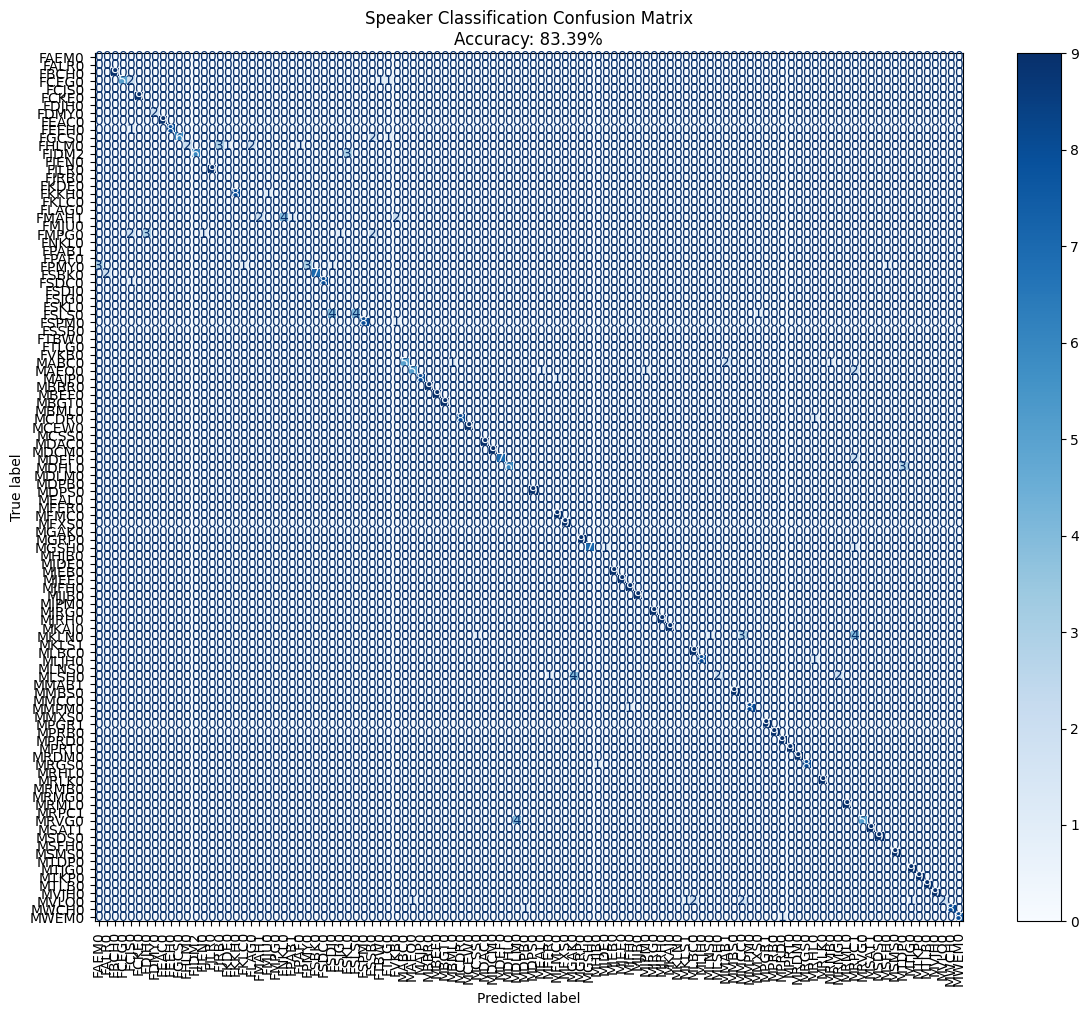

Classification results saved to: ../data/evaluation/speaker_classification_results.csv
Confusion matrix saved to: ../data/evaluation/speaker_confusion_matrix.csv


In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from pathlib import Path

if not results_df.empty:
    # Calculate accuracy
    accuracy = accuracy_score(
        results_df["target_speaker"],
        results_df["predicted_speaker"]
    )

    print(f"Evaluated files: {len(results_df)}")
    print(f"Speaker classification accuracy: {accuracy:.4f}")
    print(f"Speaker classification accuracy (%): {accuracy * 100:.2f}%")

    # Generate confusion matrix
    labels = sorted(
        set(results_df["target_speaker"]) |
        set(results_df["predicted_speaker"])
    )

    cm = confusion_matrix(
        results_df["target_speaker"],
        results_df["predicted_speaker"],
        labels=labels
    )

    print("\nConfusion Matrix:")
    print(cm)

    # Plot confusion matrix
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    fig, ax = plt.subplots(figsize=(12, 10))
    display.plot(
        ax=ax,
        xticks_rotation="vertical",
        cmap="Blues",
        values_format="d",
        colorbar=True
    )

    plt.title(
        f"Speaker Classification Confusion Matrix\n"
        f"Accuracy: {accuracy * 100:.2f}%"
    )
    plt.tight_layout()
    plt.show()

    # Save results
    results_path = Path(
        "../data/evaluation/speaker_classification_results.csv"
    )
    results_path.parent.mkdir(parents=True, exist_ok=True)
    results_df.to_csv(results_path, index=False)

    # Save confusion matrix as CSV
    cm_df = pd.DataFrame(
        cm,
        index=labels,
        columns=labels
    )
    cm_path = Path("../data/evaluation/speaker_confusion_matrix.csv")
    cm_df.to_csv(cm_path)

    print("Classification results saved to:", results_path)
    print("Confusion matrix saved to:", cm_path)

else:
    print("No files were evaluated. Check target speaker IDs and profiles.")